# BiomedCLIP + METER 근사 실험 (Expert-CFG Table 1의 BiomedCLIP 행)

> **동일 재현이 아닙니다.** BiomedCLIP 논문(Table 11)은 공개되지 않은 **ViT-B/16-448** 모델을 METER로 fine-tuning했습니다.
> 448 가중치·VQA 코드·학습 설정은 공개되지 않았습니다. 이 노트북은 **공개된 것만으로 가능한 한 가깝게** 만든 실험이며,
> 모든 결과에 `deviations`가 함께 기록됩니다.

| Dataset | 논문 Open / Closed / Overall |
|---|---|
| VQA-RAD (train 3064 / test 451) | 67.6 / 79.8 / 75.2 |
| SLAKE 영어 (train 4919 / val 1053 / test 1061) | 82.5 / 89.7 / 85.4 |

**무엇이 같고 무엇이 다른가**

| 항목 | 이 노트북 | 근거 |
|---|---|---|
| 인코더 | BiomedCLIP ViT-B/16 + PubMedBERT, 공개 **224** 가중치(HF revision 고정, 전체 fine-tuning) | 논문은 448 변형 사용(비공개) |
| Fusion | METER co-attention 6층(self→cross→FFN), CLS pooler, VQA head(1536→1536→LN→GELU→답) 직접 구현, 랜덤 초기화 | METER 공식 코드 구조 |
| 학습 설정 | AdamW lr 5e-6, cross-modal ×5, head ×50, wd 0.01, warmup 10% + linear decay, BCE×라벨 수, 질문 32 token, RAD batch 64·50 epoch, SLAKE batch 32·15 epoch, 증강 없음 | 논문에 없음 → METER 기반 의료 VQA인 **M3AE** 공식 config |
| 답 사전 | 모든 split의 정규화된 답(RAD 498개, SLAKE 222개 = M3AE와 동일) | M3AE / QCR 방식 |
| 데이터 | PubMedCLIP QCR 재현과 **같은 파일**(VQA-RAD 3064/451, SLAKE 영어) | 같은 비교 조건 |
| 평가 | 매 epoch test, **최고 epoch**(QCR·M3AE 방식) + 마지막 epoch + SLAKE validation 선택 epoch | 논문에 없음 |

`IMAGE_SIZE=448`을 고르면 METER처럼 224 위치 임베딩을 보간해 448로 fine-tuning합니다.
논문 입력 해상도에는 더 가깝지만, 448로 사전학습된 가중치와 같아지는 것은 아닙니다. 시간은 약 4배 걸립니다.

GPU 런타임에서 위부터 실행하세요. epoch마다 `last.pt`를 저장하므로, 같은 런타임에서 다시 실행하면 이어서 학습합니다.


## 1. 환경 설치


In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm==1.0.15'])
import torch
assert torch.cuda.is_available(), '런타임 > 런타임 유형 변경 > GPU'
print(torch.__version__, torch.cuda.get_device_name(0))


2.10.0+cu128 Tesla T4


## 2. 코드

저장소의 `qcr_port.py`(데이터 고정·검증)와 `biomedclip_meter.py`(모델·학습)가 그대로 들어 있습니다.


In [2]:
from pathlib import Path
import sys, importlib
CODE_ROOT = Path('/content/biomedclip_code')
CODE_ROOT.mkdir(exist_ok=True)
(CODE_ROOT / 'qcr_port.py').write_text('"""Run the official PubMedCLIP QCR code on a current Colab GPU runtime.\n\nThe official code (sarahESL/PubMedCLIP, QCR_PubMedCLIP, pinned commit) is cloned and\nonly environment-compatibility edits are applied (see PATCHES). Model, loss, optimizer,\ndata preprocessing scripts and configs are the authors\' own. Every external asset is\npinned to an exact revision (HF revision or git commit) and verified by SHA-256.\n"""\nimport hashlib\nimport json\nimport re\nimport shutil\nimport subprocess\nimport sys\nimport zipfile\nfrom pathlib import Path, PurePosixPath\n\nQCR_REPO = \'https://github.com/sarahESL/PubMedCLIP.git\'\nQCR_COMMIT = \'bdecf3c5a21b68200a02dc05455b3882a23206a2\'\n\n# repo, repo_type, revision, filename, sha256\nASSETS = {\n    \'mevf_rad\': (\'aiozai/MEVF\', \'dataset\', \'7b3bd1b1ef8965eb35ff61a1f6fada25377765ea\', \'data_RAD.zip\',\n                 \'b75d664c3dac7096a695e3a8a2b309769804f5add7e72b15e037ea9e5b839a9f\'),\n    \'slake_imgs\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'imgs.zip\',\n                   \'44eb7d9214e1ac5b7946e237b669401866df9114fd9a3618c5a84fbffcded0b0\'),\n    \'slake_train\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'train.json\',\n                    \'7a9fb81f9d7bb145c3d7e9bc8d3b9016ba18b6539ea5031a53bae8fd3cd991c3\'),\n    \'slake_test\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'test.json\',\n                   \'6be8f7b4c5a46cdbc713a5210a25b6ed5aa1fd1574c83cefb4f998131f17c2c3\'),\n    \'RN50\': (\'sarahESL/PubMedCLIP\', \'model\', \'c5885a5c0ba8ac8d86341e57c8466e49783874c1\', \'PubMedCLIP_RN50.pth\',\n             \'bb8b2bfd7f6e38fb7fb1861d969e4df862776f605aede4ecb200d2e72f9d4c6a\'),\n    \'ViT\': (\'sarahESL/PubMedCLIP\', \'model\', \'c5885a5c0ba8ac8d86341e57c8466e49783874c1\', \'PubMedCLIP_ViT32.pth\',\n            \'56d244ea2e547b59fd0357eb17d481240eeb21590e5bae2c91ea0a55de82d9c6\'),\n}\n\n# Expert-CFG Table 1 PubMedCLIP rows = PubMedCLIP paper Table 1 (QCR + AE): [open, closed, overall].\nRUNS = {\n    \'rad\': {\'encoder\': \'RN50\', \'config\': \'qcr_pubmedclipRN50_ae_rad_16batchsize_withtfidf_nondeterministic.yaml\',\n            \'paper\': [60.10, 80.00, 72.10], \'counts\': {\'train\': 3064, \'test\': 451}},\n    \'slake\': {\'encoder\': \'ViT\', \'config\': \'qcr_pubmedclipViT_ae_slake_16batchsize_withtfidf_nondeterministic.yaml\',\n              \'paper\': [78.40, 82.50, 80.10], \'counts\': {\'train\': 4919, \'test\': 1061}},\n}\n\n# The original QCR authors\' repository ships the prepared VQA-RAD bundle (data/). PubMedCLIP\'s\n# QCR code at QCR_COMMIT hard-codes its label space (487 = 56 closed + 431 open, open labels\n# indexed locally) and its type classifier was trained on that 1177-word dictionary; the\n# PubMedCLIP create_label.py/create_dictionary.py would instead produce 64+483 labels and\n# 1259 words, which the code cannot load. Train/test JSON, imgid2idx, auto-encoder and\n# images128 are byte-identical to the MEVF bundle on HF (aiozai/MEVF data_RAD.zip).\nORIGINAL_QCR_REPO = \'https://github.com/Awenbocc/med-vqa.git\'\nORIGINAL_QCR_COMMIT = \'0cca6811e38cf54aff6a7cce3442296d07875e64\'\nRAD_SHA256 = {\n    \'trainset.json\': \'3b0567673ae224b6489ca1bc4ce05cda642223d5cf4f17db8fbf7010c872e00f\',\n    \'testset.json\': \'3d32a047592cb680e18054030b38b1a44d6b17105fc62d3088c8655d56a00ced\',\n    \'imgid2idx.json\': \'4ee2f8ebc4adf3700c10307c0b3daac3edafaf08717b4d20eef423228e316257\',\n    \'dictionary.pkl\': \'35a01367a5d5a4417d6f99c045bf8f3ccca51bb48da0e37e1aae38590cc40504\',\n    \'glove6b_init_300d.npy\': \'7b70281a90e0b141d4655481718a99f9d3f09da23d2f10608e874173c1057bf1\',\n    \'embed_tfidf_weights.pkl\': \'0bb3cbb06714f8987886abffe69e0d38bf312ce7b9406b2b804915a568fcfd27\',\n    \'images128x128.pkl\': \'136cffd2c2222993c9cc7035ded0fa11d7ce1cae37ab0baaa951f85a002c6e6f\',\n    \'pretrained_ae.pth\': \'f2fb0fdc6d014fb49b85fcd2029902e14db9b42d21f3718d1a07d7082960bd05\',\n    \'cache/close_label2ans.pkl\': \'b50f9d24cb6a54599ffda7b371f3f42419be42aa5c58f9069d531cf7ffe9d863\',\n    \'cache/open_label2ans.pkl\': \'965340e4b4e9ad152e7d055987f25cafe630666d70b6fee795ccc526d28a1f4a\',\n    \'cache/trainval_ans2label.pkl\': \'daaebd434b2d1e06d79aebf24d750adca76dcb1e4548ada83a16aee0848b6b77\',\n    \'cache/trainval_label2ans.pkl\': \'22bd133cc95f2d2c25973db5e463e0c3a603c84ea4404bec1020299b8d587e83\',\n    \'cache/train_openclose_target.pkl\': \'2b99f7ade3d38d0fb5da77a4af65f8afb505f1afb5657e2b23623126c602edf5\',\n    \'cache/test_openclose_target.pkl\': \'4df33f0095ea260d91b6525d3318281c8313cebf28f0dd5c56d363635342c09b\',\n}\n\n# Inserted into lib/utils/utils.py. Globals were audited with pickletools on the pinned file.\nTFIDF_LOADER = \'\'\'string_classes = (str, bytes)\nimport pickle as _pickle\nimport types as _types\ntry:  # referenced by the PyTorch 0.4 pickle of embed_tfidf_weights.pkl\n    import torch.nn.backends.thnn\nexcept ImportError:\n    import sys as _sys\n    _thnn = _types.ModuleType(\'torch.nn.backends.thnn\')\n    _thnn._get_thnn_function_backend = lambda: None\n    _sys.modules[\'torch.nn.backends.thnn\'] = _thnn\n_TFIDF_GLOBALS = {(\'collections\', \'OrderedDict\'), (\'language_model\', \'WordEmbedding\'),\n                  (\'language.language_model\', \'WordEmbedding\'),  # file written by QCR itself (SLAKE)\n                  (\'__builtin__\', \'set\'), (\'builtins\', \'set\'),\n                  (\'torch\', \'FloatStorage\'), (\'torch._utils\', \'_rebuild_parameter\'),\n                  (\'torch._utils\', \'_rebuild_tensor_v2\'), (\'torch.nn.backends.thnn\', \'_get_thnn_function_backend\'),\n                  (\'torch.nn.modules.dropout\', \'Dropout\'), (\'torch.nn.modules.sparse\', \'Embedding\')}\nclass _AllowlistUnpickler(_pickle.Unpickler):\n    def find_class(self, module, name):\n        if (module, name) not in _TFIDF_GLOBALS:\n            raise _pickle.UnpicklingError(\'Blocked global in embed_tfidf_weights.pkl: %s.%s\' % (module, name))\n        return super().find_class(module, name)\n_tfidf_pickle = _types.ModuleType(\'qcr_allowlist_pickle\')\n_tfidf_pickle.Unpickler = _AllowlistUnpickler\n_tfidf_pickle.load = lambda f, **kw: _AllowlistUnpickler(f, **kw).load()\n\'\'\'\n\n# (file, old, new, reason). Each `old` must occur exactly once in the pinned commit.\nPATCHES = [\n    (\'lib/utils/utils.py\', \'from torch._six import string_classes\\n\', TFIDF_LOADER,\n     \'torch._six was removed in PyTorch 2; also defines the allowlisted loader used below\'),\n    (\'lib/utils/utils.py\', \'collections.Mapping)\', \'collections.abc.Mapping)\', \'Python 3.10 removed collections.Mapping\'),\n    (\'lib/utils/utils.py\', \'collections.Sequence)\', \'collections.abc.Sequence)\', \'Python 3.10 removed collections.Sequence\'),\n    (\'lib/utils/utils.py\', \'w_emb = torch.load(f)\\n\',\n     \'w_emb = torch.load(f, weights_only=False, pickle_module=_tfidf_pickle)\\n\',\n     \'embed_tfidf_weights.pkl is a PyTorch-0.4 pickled nn.Module; PyTorch>=2.6 defaults to weights_only=True. \'\n     \'Load it with an unpickler that only allows the audited classes\'),\n    (\'lib/utils/utils.py\', \'torch.sparse.FloatTensor(torch.LongTensor(inds), torch.FloatTensor(vals))\',\n     \'torch.sparse_coo_tensor(torch.LongTensor(inds), torch.FloatTensor(vals))\', \'legacy sparse constructor\'),\n    (\'lib/utils/create_label.py\', \'qa_pairs = train_qa_pairs.append(val_qa_pairs)\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n\\n    for id\',\n     \'qa_pairs = pd.concat([train_qa_pairs, val_qa_pairs])\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n\\n    for id\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_label.py\', \'qa_pairs = train_qa_pairs.append(val_qa_pairs)\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n    qa_pairs_open\',\n     \'qa_pairs = pd.concat([train_qa_pairs, val_qa_pairs])\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n    qa_pairs_open\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_label.py\', \'df = train_qa_pairs.append(val_qa_pairs)\', \'df = pd.concat([train_qa_pairs, val_qa_pairs])\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_img2idx.py\', \'df = train_en.append(val_en)\', \'df = pd.concat([train_en, val_en])\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/BAN/multi_level_model.py\',\n     "            self.clip, _ = clip.load(cfg.TRAIN.VISION.CLIP_VISION_ENCODER, jit=False)\\n"\n     "            if not cfg.TRAIN.VISION.CLIP_ORG:\\n"\n     "                checkpoint = torch.load(cfg.TRAIN.VISION.CLIP_PATH)\\n"\n     "                self.clip.load_state_dict(checkpoint[\'state_dict\'])\\n",\n     "            if not cfg.TRAIN.VISION.CLIP_ORG:\\n"\n     "                checkpoint = torch.load(cfg.TRAIN.VISION.CLIP_PATH, map_location=\'cpu\')\\n"\n     "                # Same as clip.load(name) + load_state_dict: build_model() casts to fp16 and the\\n"\n     "                # PubMedCLIP weights are copied into those fp16 parameters before .float().\\n"\n     "                self.clip = clip.model.build_model(checkpoint[\'state_dict\']).to(device)\\n"\n     "                self.clip.load_state_dict(checkpoint[\'state_dict\'])\\n"\n     "            else:\\n"\n     "                self.clip, _ = clip.load(cfg.TRAIN.VISION.CLIP_VISION_ENCODER, jit=False)\\n",\n     \'clip.load(name) first downloads OpenAI weights (openaipublic.azureedge.net CDN) that are immediately \'\n     \'overwritten; build the identical architecture from the PubMedCLIP state dict instead\'),\n    (\'main/classifier.py\', \'nn.Dropout(cfg.TRAIN.DROPOUT, inplace=True)\', \'nn.Dropout(cfg.TRAIN.DROPOUT, inplace=False)\',\n     \'current autograd rejects in-place dropout on the saved ReLU output; out-of-place dropout gives the same \'\n     \'forward values and gradients (dropped units get zero gradient either way)\'),\n    (\'main/train.py\',\n     "                utils.save_model(model_path, model, best_epoch, eval_score, open_score, close_score, optim)\\n",\n     "                utils.save_model(model_path, model, best_epoch, eval_score, open_score, close_score, optim)\\n"\n     "                if os.environ.get(\'QCR_KEEP_ALL_BEST\', \'0\') != \'1\':\\n"\n     "                    for old in os.listdir(ckpt_path):\\n"\n     "                        if old.endswith(\'_best.pth\') and old != os.path.basename(model_path):\\n"\n     "                            os.remove(os.path.join(ckpt_path, old))\\n",\n     \'each improvement saves a ~1 GB checkpoint (CLIP + optimizer); keep only the newest one so 200 epochs fit \'\n     \'on Colab disk (file handling only; QCR_KEEP_ALL_BEST=1 restores the original behaviour)\'),\n    (\'main/main.py\', \'    torch.autograd.set_detect_anomaly(True)\\n\',\n     \'    torch.autograd.set_detect_anomaly(os.environ.get("QCR_DETECT_ANOMALY", "0") == "1")\\n\',\n     \'anomaly detection is a debugging aid (no numerical effect) that slows training several times; \'\n     \'set QCR_DETECT_ANOMALY=1 to restore it\'),\n]\n\n\ndef sha256(path, chunk=1 << 22):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for block in iter(lambda: f.read(chunk), b\'\'):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef run(cmd, cwd=None, env=None):\n    import os\n    print(\'$\', \' \'.join(map(str, cmd)), flush=True)\n    # The authors\' scripts open GloVe/JSON with the platform default encoding.\n    env = dict(env or os.environ, PYTHONUTF8=\'1\', PYTHONUNBUFFERED=\'1\')\n    # Stream through Python so the output is visible in a notebook cell.\n    with subprocess.Popen(list(map(str, cmd)), cwd=cwd, env=env, stdout=subprocess.PIPE,\n                          stderr=subprocess.STDOUT, text=True, encoding=\'utf-8\', errors=\'replace\') as proc:\n        for line in proc.stdout:\n            print(line, end=\'\', flush=True)\n    if proc.returncode:\n        raise subprocess.CalledProcessError(proc.returncode, cmd)\n\n\ndef fetch(key, cache_dir):\n    from huggingface_hub import hf_hub_download\n    repo, repo_type, revision, filename, expected = ASSETS[key]\n    path = Path(hf_hub_download(repo, filename, repo_type=repo_type, revision=revision, cache_dir=str(cache_dir)))\n    if expected and sha256(path) != expected:\n        raise ValueError(f\'SHA-256 mismatch for {repo}/{filename}@{revision}\')\n    return path\n\n\ndef safe_extract(zip_path, target):\n    target = Path(target)\n    with zipfile.ZipFile(zip_path) as archive:\n        for member in archive.infolist():\n            name = PurePosixPath(member.filename)\n            if name.is_absolute() or \'..\' in name.parts or \'\\\\\' in member.filename:\n                raise ValueError(\'Unsafe archive member: \' + member.filename)\n        archive.extractall(target)\n\n\ndef setup_code(work_dir, source=None):\n    """Clone the pinned official repo (or copy a local clone) and apply PATCHES."""\n    work_dir = Path(work_dir)\n    repo_root = work_dir / \'PubMedCLIP\'\n    if not repo_root.exists():\n        if source:\n            shutil.copytree(source, repo_root, ignore=shutil.ignore_patterns(\'.git\'))\n        else:\n            run([\'git\', \'clone\', \'--quiet\', QCR_REPO, repo_root])\n            run([\'git\', \'checkout\', \'--quiet\', QCR_COMMIT], cwd=repo_root)\n    if (repo_root / \'.git\').exists():\n        head = subprocess.run([\'git\', \'rev-parse\', \'HEAD\'], cwd=repo_root, capture_output=True, text=True, check=True).stdout.strip()\n        if head != QCR_COMMIT:\n            raise ValueError(f\'Expected QCR commit {QCR_COMMIT}, found {head}\')\n    qcr = repo_root / \'QCR_PubMedCLIP\'\n    applied = []\n    for rel, old, new, reason in PATCHES:\n        path = qcr / rel\n        text = path.read_text(encoding=\'utf-8\')\n        if text.count(old) == 1:\n            path.write_text(text.replace(old, new), encoding=\'utf-8\')\n        elif not (text.count(old) == 0 and new in text):\n            raise ValueError(f\'Patch target not found exactly once in {rel}: {old[:60]!r}\')\n        applied.append({\'file\': rel, \'reason\': reason})\n    return qcr, applied\n\n\ndef _check_counts(dataset, data_dir):\n    if dataset == \'rad\':\n        train = json.loads((data_dir / \'trainset.json\').read_text(encoding=\'utf-8\'))\n        test = json.loads((data_dir / \'testset.json\').read_text(encoding=\'utf-8\'))\n    else:\n        train = [r for r in json.loads((data_dir / \'train.json\').read_text(encoding=\'utf-8\')) if r[\'q_lang\'] == \'en\']\n        test = [r for r in json.loads((data_dir / \'test.json\').read_text(encoding=\'utf-8\')) if r[\'q_lang\'] == \'en\']\n    counts = {\'train\': len(train), \'test\': len(test)}\n    if counts != RUNS[dataset][\'counts\']:\n        raise ValueError(f\'{dataset}: expected {RUNS[dataset]["counts"]}, got {counts}\')\n    return counts\n\n\ndef _clone_original_qcr(work_dir):\n    repo = Path(work_dir) / \'med-vqa\'\n    if not repo.exists():\n        run([\'git\', \'clone\', \'--quiet\', ORIGINAL_QCR_REPO, repo])\n    run([\'git\', \'checkout\', \'--quiet\', ORIGINAL_QCR_COMMIT], cwd=repo)\n    return repo\n\n\ndef _extract_member(zip_path, member, target):\n    target = Path(target)\n    target.parent.mkdir(parents=True, exist_ok=True)\n    with zipfile.ZipFile(zip_path) as archive, archive.open(member) as src, open(target, \'wb\') as dst:\n        shutil.copyfileobj(src, dst, 1 << 22)\n\n\ndef prepare_data(qcr, dataset, cache_dir):\n    """Create data/data_rad or data/data_slake as the QCR code at QCR_COMMIT expects."""\n    qcr, cache_dir = Path(qcr), Path(cache_dir)\n    data_root = qcr / \'data\'\n    rad_dir, slake_dir = data_root / \'data_rad\', data_root / \'data_slake\'\n    utils_dir = qcr / \'lib\' / \'utils\'\n    py = sys.executable\n    marker = data_root / f\'.{dataset}_ready\'\n    if marker.exists():\n        return json.loads(marker.read_text(encoding=\'utf-8\'))\n    if dataset == \'rad\':\n        source = _clone_original_qcr(qcr.parent.parent) / \'data\'\n        if rad_dir.exists():\n            shutil.rmtree(rad_dir)\n        shutil.copytree(source, rad_dir, ignore=shutil.ignore_patterns(\'*.ipynb\', \'.ipynb_checkpoints\'))\n        for rel, expected in RAD_SHA256.items():\n            if sha256(rad_dir / rel) != expected:\n                raise ValueError(f\'Original QCR RAD file changed: {rel}\')\n        counts = _check_counts(\'rad\', rad_dir)\n        # The only input missing from the bundle: CLIP images, made with PubMedCLIP\'s own script\n        # exactly as in lib/utils/run.sh (250x250, 3 channels).\n        run([py, \'create_resized_images.py\', rad_dir / \'imgid2idx.json\', rad_dir / \'images\',\n             250, rad_dir / \'images250x250.pkl\', 3], cwd=utils_dir)\n        assets = {\'original_qcr\': [ORIGINAL_QCR_REPO, ORIGINAL_QCR_COMMIT, \'data/\']}\n    elif dataset == \'slake\':\n        # lib/utils/run.sh, SLAKE part. GloVe 6B-300d and the pretrained auto-encoder come from the\n        # MEVF bundle on HF (the same auto-encoder file as the RAD bundle; QCR ships no SLAKE one).\n        mevf = fetch(\'mevf_rad\', cache_dir)\n        glove = data_root / \'glove.6B\' / \'glove.6B.300d.txt\'\n        if not glove.exists():\n            _extract_member(mevf, \'glove/glove.6B.300d.txt\', glove)\n        slake_dir.mkdir(parents=True, exist_ok=True)\n        _extract_member(mevf, \'pretrained_ae.pth\', slake_dir / \'pretrained_ae.pth\')\n        if sha256(slake_dir / \'pretrained_ae.pth\') != RAD_SHA256[\'pretrained_ae.pth\']:\n            raise ValueError(\'Unexpected auto-encoder checkpoint\')\n        for key, name in ((\'slake_train\', \'train.json\'), (\'slake_test\', \'test.json\')):\n            shutil.copyfile(fetch(key, cache_dir), slake_dir / name)\n        if not (slake_dir / \'imgs\').exists():\n            safe_extract(fetch(\'slake_imgs\', cache_dir), slake_dir)\n        counts = _check_counts(\'slake\', slake_dir)\n        run([py, \'create_dictionary.py\', slake_dir.as_posix()], cwd=utils_dir)\n        run([py, \'create_label.py\', slake_dir.as_posix() + \'/\'], cwd=utils_dir)\n        run([py, \'create_img2idx.py\', slake_dir / \'train.json\', slake_dir / \'test.json\', slake_dir / \'imgid2idx.json\'], cwd=utils_dir)\n        for size, channels in ((128, 1), (250, 3)):\n            run([py, \'create_resized_images.py\', slake_dir / \'imgid2idx.json\', slake_dir / \'imgs\',\n                 size, slake_dir / f\'images{size}x{size}.pkl\', channels], cwd=utils_dir)\n        assets = {k: list(ASSETS[k][:4]) for k in (\'mevf_rad\', \'slake_imgs\', \'slake_train\', \'slake_test\')}\n    else:\n        raise ValueError(\'dataset must be rad or slake\')\n    info = {\'dataset\': dataset, \'counts\': counts, \'assets\': assets}\n    marker.write_text(json.dumps(info, indent=2), encoding=\'utf-8\')\n    return info\n\n\ndef make_config(qcr, dataset, clip_path, run_index, n_epoch=None):\n    """Copy the authors\' config; only CLIP_PATH, the run NAME and (quick checks only) N_EPOCH change."""\n    qcr = Path(qcr)\n    spec = RUNS[dataset]\n    text = (qcr / \'configs\' / spec[\'config\']).read_text(encoding=\'utf-8\')\n    text, n = re.subn(r\'CLIP_PATH: ".*"\', f\'CLIP_PATH: "{Path(clip_path).as_posix()}"\', text)\n    assert n == 1\n    suffix = f\'.run{run_index}\' + (f\'.epochs{n_epoch}\' if n_epoch else \'\')\n    text, n = re.subn(r"^NAME: \'(.*)\'", lambda m: f"NAME: \'{m.group(1)}{suffix}\'", text, flags=re.M)\n    assert n == 1\n    if n_epoch:\n        text, n = re.subn(r\'N_EPOCH: \\d+\', f\'N_EPOCH: {int(n_epoch)}\', text)\n        assert n == 1\n    out = qcr / \'configs\' / f\'repro_{dataset}{suffix}.yaml\'\n    out.write_text(text, encoding=\'utf-8\')\n    return out\n\n\ndef config_value(config_path, key):\n    match = re.search(rf\'^\\s*{key}:\\s*[\\\'"]?([^\\\'"\\n#]+)\', Path(config_path).read_text(encoding=\'utf-8\'), re.M)\n    return match.group(1).strip()\n\n\nVAL_RE = re.compile(r\'\\[Validate\\] Val_Acc:([\\d.]+)%\\s*\\|\\s*Open_ACC:([\\d.]+)%\\s*\\|\\s*Close_ACC:([\\d.]+)%\')\n\n\ndef parse_log(log_path):\n    """Per-epoch test accuracy from medVQA.log; best epoch selected exactly as train.py does."""\n    epochs = [{\'epoch\': i, \'overall\': float(a), \'open\': float(o), \'closed\': float(c)}\n              for i, (a, o, c) in enumerate(VAL_RE.findall(Path(log_path).read_text(encoding=\'utf-8\', errors=\'replace\')))]\n    best = None\n    for row in epochs:  # train.py keeps the first epoch with a strictly higher overall accuracy\n        if row[\'overall\'] > (best[\'overall\'] if best else 0):\n            best = row\n    return {\'epochs_logged\': len(epochs), \'best\': best, \'last\': epochs[-1] if epochs else None}\n\n\ndef train(qcr, dataset, clip_path, run_index=0, n_epoch=None, anomaly=False, keep_all_best=False):\n    """Run the authors\' main/main.py with their config (see make_config) and parse its log."""\n    import os\n    qcr = Path(qcr)\n    config = make_config(qcr, dataset, clip_path, run_index, n_epoch)\n    env = dict(os.environ, QCR_DETECT_ANOMALY=\'1\' if anomaly else \'0\', QCR_KEEP_ALL_BEST=\'1\' if keep_all_best else \'0\')\n    run([sys.executable, \'main/main.py\', \'--cfg\', config.relative_to(qcr).as_posix()], cwd=qcr, env=env)\n    out = qcr / config_value(config, \'OUTPUT_DIR\') / config_value(config, \'NAME\')\n    result = parse_log(out / \'medVQA.log\')\n    expected_epochs = int(config_value(config, \'N_EPOCH\'))\n    result.update(dataset=dataset, encoder=RUNS[dataset][\'encoder\'], run=run_index, config=config.name,\n                  full_protocol=n_epoch is None and result[\'epochs_logged\'] == expected_epochs,\n                  paper_open_closed_overall=RUNS[dataset][\'paper\'], output_dir=str(out))\n    (out / \'result.json\').write_text(json.dumps(result, indent=2), encoding=\'utf-8\')\n    return result\n\n\ndef summarize(results):\n    """Mean/std over runs of each run\'s best-epoch test accuracy (the authors\' protocol) and last epoch."""\n    import statistics\n    table = {}\n    for dataset in RUNS:\n        rows = [r for r in results if r[\'dataset\'] == dataset and r[\'best\']]\n        if not rows:\n            continue\n        entry = {\'runs\': len(rows), \'full_protocol\': all(r[\'full_protocol\'] for r in rows),\n                 \'paper_open_closed_overall\': RUNS[dataset][\'paper\']}\n        for key in (\'open\', \'closed\', \'overall\'):\n            values = [r[\'best\'][key] for r in rows]\n            entry[key] = statistics.mean(values)\n            entry[key + \'_std\'] = statistics.stdev(values) if len(values) > 1 else 0.0\n            entry[\'last_epoch_\' + key] = statistics.mean(r[\'last\'][key] for r in rows)\n        table[dataset] = entry\n    return table\n', encoding='utf-8')
(CODE_ROOT / 'biomedclip_meter.py').write_text('"""BiomedCLIP + METER-style VQA on VQA-RAD / SLAKE: an APPROXIMATION of the BiomedCLIP paper row.\n\nThe BiomedCLIP paper (Table 11) fine-tunes "ViT-B/16-448-PMB/256" with METER but releases neither\nthe 448 checkpoint nor VQA code/hyper-parameters. This module therefore:\n  * uses the public BiomedCLIP checkpoint (ViT-B/16-224 + PubMedBERT), pinned revision;\n  * re-implements the METER co-attention fusion (zdou0830/METER: 6 BertCrossLayers per modality,\n    CLS poolers, VQA head) with randomly initialised fusion, full fine-tuning of both encoders;\n  * fills every unstated setting from M3AE (zhjohnchan/M3AE, a METER-based medical VQA code base):\n    AdamW lr 5e-6, x5 cross-modal, x50 head, wd 0.01, 10% warm-up + linear decay, BCE x labels,\n    answer set = all normalised answers of every split, max 32 question tokens,\n    VQA-RAD batch 64 / 50 epochs, SLAKE batch 32 / 15 epochs;\n  * evaluates like QCR/M3AE (test accuracy every epoch, best epoch reported) and also records the\n    last epoch and, for SLAKE, the epoch chosen on the official validation split.\nData: the same VQA-RAD 3064/451 and SLAKE English files as the PubMedCLIP QCR reproduction (qcr_port).\n"""\nimport json\nimport math\nimport random\nimport re\nimport shutil\nfrom collections import Counter\nfrom pathlib import Path\n\nimport qcr_port\n\nBIOMEDCLIP = (\'microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224\', \'9f341de24bfb00180f1b847274256e9b65a3a32e\',\n              \'open_clip_pytorch_model.bin\', \'52cc993c5c5ff962bd0c60931874bc001e7e9b41666a385530f4a036294576be\')\nTEXT_CONFIG = (\'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract\', \'d673b8835373c6fa116d6d8006b33d48734e305d\')\nSLAKE_VALIDATION = (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'validation.json\',\n                    \'32b016440b0c3be11056a78a18eeab46333268407fbb6e6b32f9f4c2debc50f6\')\nqcr_port.ASSETS.setdefault(\'slake_validation\', SLAKE_VALIDATION)\nCLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)\n\n# BiomedCLIP paper Table 11 (METER row) = Expert-CFG Table 1 BiomedCLIP row: [open, closed, overall].\nPAPER = {\'rad\': [67.60, 79.80, 75.20], \'slake\': [82.50, 89.70, 85.40]}\nCOUNTS = {\'rad\': {\'train\': 3064, \'test\': 451}, \'slake\': {\'train\': 4919, \'validation\': 1053, \'test\': 1061}}\n# M3AE task_finetune_vqa_vqa_rad / task_finetune_vqa_slack (+ METER defaults for the rest).\nDEFAULTS = {\n    \'rad\': dict(batch_size=64, epochs=50),\n    \'slake\': dict(batch_size=32, epochs=15),\n    \'common\': dict(learning_rate=5e-6, lr_mult_cross_modal=5, lr_mult_head=50, weight_decay=0.01, warmup=0.1,\n                   betas=(0.9, 0.98), eps=1e-8, max_text_len=32, image_size=224, num_top_layer=6, hidden_size=768,\n                   num_heads=12, mlp_ratio=4, drop_rate=0.1, micro_batch=16, seed=0, amp=True, grad_checkpointing=True, num_workers=2),\n}\n\n# ---- VQA answer normalisation (M3AE prepro/glossary.py normalize_word; same tables as QCR create_label.py)\nCONTRACTIONS = {\'aint\': "ain\'t", \'arent\': "aren\'t", \'cant\': "can\'t", \'couldve\': "could\'ve", \'couldnt\': "couldn\'t", "couldn\'tve": "couldn\'t\'ve", "couldnt\'ve": "couldn\'t\'ve", \'didnt\': "didn\'t", \'doesnt\': "doesn\'t", \'dont\': "don\'t", \'hadnt\': "hadn\'t", "hadnt\'ve": "hadn\'t\'ve", "hadn\'tve": "hadn\'t\'ve", \'hasnt\': "hasn\'t", \'havent\': "haven\'t", \'hed\': "he\'d", "hed\'ve": "he\'d\'ve", "he\'dve": "he\'d\'ve", \'hes\': "he\'s", \'howd\': "how\'d", \'howll\': "how\'ll", \'hows\': "how\'s", "Id\'ve": "I\'d\'ve", "I\'dve": "I\'d\'ve", \'Im\': "I\'m", \'Ive\': "I\'ve", \'isnt\': "isn\'t", \'itd\': "it\'d", "itd\'ve": "it\'d\'ve", "it\'dve": "it\'d\'ve", \'itll\': "it\'ll", "let\'s": "let\'s", \'maam\': "ma\'am", \'mightnt\': "mightn\'t", "mightnt\'ve": "mightn\'t\'ve", "mightn\'tve": "mightn\'t\'ve", \'mightve\': "might\'ve", \'mustnt\': "mustn\'t", \'mustve\': "must\'ve", \'neednt\': "needn\'t", \'notve\': "not\'ve", \'oclock\': "o\'clock", \'oughtnt\': "oughtn\'t", "ow\'s\'at": "\'ow\'s\'at", "\'ows\'at": "\'ow\'s\'at", "\'ow\'sat": "\'ow\'s\'at", \'shant\': "shan\'t", "shed\'ve": "she\'d\'ve", "she\'dve": "she\'d\'ve", "she\'s": "she\'s", \'shouldve\': "should\'ve", \'shouldnt\': "shouldn\'t", "shouldnt\'ve": "shouldn\'t\'ve", "shouldn\'tve": "shouldn\'t\'ve", "somebody\'d": \'somebodyd\', "somebodyd\'ve": "somebody\'d\'ve", "somebody\'dve": "somebody\'d\'ve", \'somebodyll\': "somebody\'ll", \'somebodys\': "somebody\'s", \'someoned\': "someone\'d", "someoned\'ve": "someone\'d\'ve", "someone\'dve": "someone\'d\'ve", \'someonell\': "someone\'ll", \'someones\': "someone\'s", \'somethingd\': "something\'d", "somethingd\'ve": "something\'d\'ve", "something\'dve": "something\'d\'ve", \'somethingll\': "something\'ll", \'thats\': "that\'s", \'thered\': "there\'d", "thered\'ve": "there\'d\'ve", "there\'dve": "there\'d\'ve", \'therere\': "there\'re", \'theres\': "there\'s", \'theyd\': "they\'d", "theyd\'ve": "they\'d\'ve", "they\'dve": "they\'d\'ve", \'theyll\': "they\'ll", \'theyre\': "they\'re", \'theyve\': "they\'ve", \'twas\': "\'twas", \'wasnt\': "wasn\'t", "wed\'ve": "we\'d\'ve", "we\'dve": "we\'d\'ve", \'weve\': "we\'ve", \'werent\': "weren\'t", \'whatll\': "what\'ll", \'whatre\': "what\'re", \'whats\': "what\'s", \'whatve\': "what\'ve", \'whens\': "when\'s", \'whered\': "where\'d", \'wheres\': "where\'s", \'whereve\': "where\'ve", \'whod\': "who\'d", "whod\'ve": "who\'d\'ve", "who\'dve": "who\'d\'ve", \'wholl\': "who\'ll", \'whos\': "who\'s", \'whove\': "who\'ve", \'whyll\': "why\'ll", \'whyre\': "why\'re", \'whys\': "why\'s", \'wont\': "won\'t", \'wouldve\': "would\'ve", \'wouldnt\': "wouldn\'t", "wouldnt\'ve": "wouldn\'t\'ve", "wouldn\'tve": "wouldn\'t\'ve", \'yall\': "y\'all", "yall\'ll": "y\'all\'ll", "y\'allll": "y\'all\'ll", "yall\'d\'ve": "y\'all\'d\'ve", "y\'alld\'ve": "y\'all\'d\'ve", "y\'all\'dve": "y\'all\'d\'ve", \'youd\': "you\'d", "youd\'ve": "you\'d\'ve", "you\'dve": "you\'d\'ve", \'youll\': "you\'ll", \'youre\': "you\'re", \'youve\': "you\'ve"}\nMANUAL_MAP = {\'none\': \'0\', \'zero\': \'0\', \'one\': \'1\', \'two\': \'2\', \'three\': \'3\', \'four\': \'4\', \'five\': \'5\', \'six\': \'6\', \'seven\': \'7\', \'eight\': \'8\', \'nine\': \'9\', \'ten\': \'10\'}\nARTICLES = [\'a\', \'an\', \'the\']\nPUNCT = [\';\', \'/\', \'[\', \']\', \'"\', \'{\', \'}\', \'(\', \')\', \'=\', \'+\', \'\\\\\', \'_\', \'-\', \'>\', \'<\', \'@\', \'`\', \',\', \'?\', \'!\']\n_PERIOD_STRIP = re.compile(r\'(?!<=\\d)(\\.)(?!\\d)\')\n_COMMA_STRIP = re.compile(r\'(\\d)(\\,)(\\d)\')\n\n\ndef normalize_answer(token):\n    token = str(token).lower()\n    _token = token\n    for p in PUNCT:\n        if (p + \' \' in token or \' \' + p in token) or (re.search(_COMMA_STRIP, token) is not None):\n            _token = _token.replace(p, \'\')\n        else:\n            _token = _token.replace(p, \' \')\n    token = _PERIOD_STRIP.sub(\'\', _token, re.UNICODE)\n    words = [MANUAL_MAP.get(w, w) for w in token.lower().split()]\n    words = [CONTRACTIONS.get(w, w) for w in words if w not in ARTICLES]\n    return \' \'.join(words).replace(\',\', \'\')\n\n\n# ---- data -----------------------------------------------------------------------------------------\ndef load_data(dataset, work_dir, cache_dir):\n    """Rows with original question/answer/answer_type; the files are those of the QCR reproduction."""\n    work_dir, cache_dir = Path(work_dir), Path(cache_dir)\n    splits = {}\n    if dataset == \'rad\':\n        repo = qcr_port._clone_original_qcr(work_dir)\n        data = repo / \'data\'\n        for name in (\'trainset.json\', \'testset.json\'):\n            if qcr_port.sha256(data / name) != qcr_port.RAD_SHA256[name]:\n                raise ValueError(\'VQA-RAD split file changed: \' + name)\n        for split in (\'train\', \'test\'):\n            rows = json.loads((data / f\'{split}set.json\').read_text(encoding=\'utf-8\'))\n            splits[split] = [dict(qid=r[\'qid\'], question=r[\'question\'], answer=str(r[\'answer\']),\n                                  answer_type=r[\'answer_type\'], image=str(data / \'images\' / r[\'image_name\'])) for r in rows]\n    elif dataset == \'slake\':\n        root = work_dir / \'slake\'\n        if not (root / \'imgs\').exists():\n            root.mkdir(parents=True, exist_ok=True)\n            qcr_port.safe_extract(qcr_port.fetch(\'slake_imgs\', cache_dir), root)\n        for split, key in ((\'train\', \'slake_train\'), (\'validation\', \'slake_validation\'), (\'test\', \'slake_test\')):\n            rows = json.loads(Path(qcr_port.fetch(key, cache_dir)).read_text(encoding=\'utf-8\'))\n            splits[split] = [dict(qid=r[\'qid\'], question=r[\'question\'], answer=str(r[\'answer\']),\n                                  answer_type=r[\'answer_type\'], image=str(root / \'imgs\' / r[\'img_name\']))\n                             for r in rows if r[\'q_lang\'] == \'en\']\n    else:\n        raise ValueError(\'dataset must be rad or slake\')\n    counts = {k: len(v) for k, v in splits.items()}\n    if counts != COUNTS[dataset]:\n        raise ValueError(f\'{dataset}: expected {COUNTS[dataset]}, got {counts}\')\n    for rows in splits.values():\n        for r in rows:\n            kind = r[\'answer_type\'].strip().upper()\n            if kind not in (\'OPEN\', \'CLOSED\'):\n                raise ValueError(f\'Bad answer_type {r["answer_type"]!r}\')\n            r[\'answer_type\'], r[\'label_text\'] = kind, normalize_answer(r[\'answer\'])\n            if not Path(r[\'image\']).exists():\n                raise FileNotFoundError(r[\'image\'])\n    # M3AE make_arrow_vqa: label set = every normalised answer of every split, in first-seen order.\n    labels = list(dict.fromkeys(r[\'label_text\'] for split in splits for r in splits[split]))\n    return splits, labels\n\n\n# ---- model ------------------------------------------------------------------------------------------\ndef build_model(num_labels, cfg, weights_path, text_config_dir):\n    import torch\n    import timm\n    from torch import nn\n    from torch.nn import functional as F\n    from transformers import BertConfig, BertModel\n    from torch.utils.checkpoint import checkpoint\n\n    hs, heads, drop = cfg[\'hidden_size\'], cfg[\'num_heads\'], cfg[\'drop_rate\']\n\n    class Attention(nn.Module):  # METER/BERT BertAttention: MHA + dense + dropout + residual LayerNorm\n        def __init__(self):\n            super().__init__()\n            self.query, self.key, self.value = nn.Linear(hs, hs), nn.Linear(hs, hs), nn.Linear(hs, hs)\n            self.dense, self.dropout, self.LayerNorm = nn.Linear(hs, hs), nn.Dropout(drop), nn.LayerNorm(hs, eps=1e-12)\n\n        def forward(self, x, context, mask):\n            b, n, _ = x.shape\n            split = lambda t: t.view(b, -1, heads, hs // heads).transpose(1, 2)\n            out = F.scaled_dot_product_attention(split(self.query(x)), split(self.key(context)), split(self.value(context)),\n                                                 attn_mask=mask, dropout_p=drop if self.training else 0.0)\n            return self.LayerNorm(self.dropout(self.dense(out.transpose(1, 2).reshape(b, n, hs))) + x)\n\n    class BertCrossLayer(nn.Module):  # METER meter/modules/bert_model.py: self-attn -> cross-attn -> FFN\n        def __init__(self):\n            super().__init__()\n            self.attention, self.crossattention = Attention(), Attention()\n            self.intermediate = nn.Linear(hs, hs * cfg[\'mlp_ratio\'])\n            self.output, self.out_dropout = nn.Linear(hs * cfg[\'mlp_ratio\'], hs), nn.Dropout(drop)\n            self.out_norm = nn.LayerNorm(hs, eps=1e-12)\n\n        def forward(self, x, y, x_mask, y_mask):\n            x = self.crossattention(self.attention(x, x, x_mask), y, y_mask)\n            return self.out_norm(self.out_dropout(self.output(F.gelu(self.intermediate(x)))) + x)\n\n    class Pooler(nn.Module):\n        def __init__(self):\n            super().__init__()\n            self.dense = nn.Linear(hs, hs)\n\n        def forward(self, x):\n            return torch.tanh(self.dense(x[:, 0]))\n\n    class BiomedCLIPMeter(nn.Module):\n        def __init__(self):\n            super().__init__()\n            state = torch.load(weights_path, map_location=\'cpu\', weights_only=True)\n            self.vision = timm.create_model(\'vit_base_patch16_224\', pretrained=False, num_classes=0, global_pool=\'\')\n            vision_state = {k[len(\'visual.trunk.\'):]: v for k, v in state.items() if k.startswith(\'visual.trunk.\')}\n            self.vision.load_state_dict(vision_state, strict=True)\n            if cfg[\'image_size\'] != 224:  # METER-style fine-tuning at higher resolution: resample pos. embeddings\n                self.vision.set_input_size(img_size=(cfg[\'image_size\'], cfg[\'image_size\']))\n            config = BertConfig.from_pretrained(text_config_dir)\n            self.text = BertModel(config, add_pooling_layer=False)\n            text_state = {k[len(\'text.transformer.\'):]: v for k, v in state.items()\n                          if k.startswith(\'text.transformer.\') and not k.endswith(\'position_ids\')}\n            missing, unexpected = self.text.load_state_dict(text_state, strict=False)\n            if unexpected or [k for k in missing if not k.endswith(\'position_ids\')]:\n                raise ValueError(f\'BiomedCLIP text weights mismatch: missing={missing}, unexpected={unexpected}\')\n            del state\n            self.cross_modal_text_transform = nn.Linear(config.hidden_size, hs)\n            self.cross_modal_image_transform = nn.Linear(self.vision.num_features, hs)\n            self.token_type_embeddings = nn.Embedding(2, hs)\n            self.cross_modal_text_layers = nn.ModuleList([BertCrossLayer() for _ in range(cfg[\'num_top_layer\'])])\n            self.cross_modal_image_layers = nn.ModuleList([BertCrossLayer() for _ in range(cfg[\'num_top_layer\'])])\n            self.cross_modal_text_pooler, self.cross_modal_image_pooler = Pooler(), Pooler()\n            self.vqa_classifier = nn.Sequential(nn.Linear(hs * 2, hs * 2), nn.LayerNorm(hs * 2), nn.GELU(),\n                                                nn.Linear(hs * 2, num_labels))\n            for name, module in self.named_children():  # METER init_weights for the new modules\n                if name not in (\'vision\', \'text\'):\n                    module.apply(self._init)\n            if cfg[\'grad_checkpointing\']:\n                self.vision.set_grad_checkpointing(True)\n                self.text.gradient_checkpointing_enable(gradient_checkpointing_kwargs={\'use_reentrant\': False})\n\n        @staticmethod\n        def _init(module):\n            if isinstance(module, (nn.Linear, nn.Embedding)):\n                module.weight.data.normal_(mean=0.0, std=0.02)\n            elif isinstance(module, nn.LayerNorm):\n                module.bias.data.zero_(); module.weight.data.fill_(1.0)\n            if isinstance(module, nn.Linear) and module.bias is not None:\n                module.bias.data.zero_()\n\n        def forward(self, pixel_values, input_ids, attention_mask):\n            text = self.text(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state\n            image = self.vision.forward_features(pixel_values)\n            text = self.cross_modal_text_transform(text) + self.token_type_embeddings.weight[0]\n            image = self.cross_modal_image_transform(image) + self.token_type_embeddings.weight[1]\n            # Boolean SDPA masks: True = attend. Images have no padding.\n            text_mask = attention_mask[:, None, None, :].bool()\n            image_mask = None\n            for text_layer, image_layer in zip(self.cross_modal_text_layers, self.cross_modal_image_layers):\n                def step(x, y, text_layer=text_layer, image_layer=image_layer):\n                    return text_layer(x, y, text_mask, image_mask), image_layer(y, x, image_mask, text_mask)\n                if cfg[\'grad_checkpointing\'] and self.training:\n                    text, image = checkpoint(step, text, image, use_reentrant=False)\n                else:\n                    text, image = step(text, image)\n            return self.vqa_classifier(torch.cat([self.cross_modal_text_pooler(text), self.cross_modal_image_pooler(image)], -1))\n\n    return BiomedCLIPMeter()\n\n\ndef param_groups(model, cfg):\n    """METER set_schedule: x lr_mult_head for the VQA head, x lr_mult_cross_modal for \'cross_modal\', no decay on bias/norm."""\n    no_decay = (\'bias\', \'LayerNorm.bias\', \'LayerNorm.weight\', \'norm.bias\', \'norm.weight\', \'norm1.bias\', \'norm1.weight\',\n                \'norm2.bias\', \'norm2.weight\', \'out_norm.weight\', \'out_norm.bias\')\n    groups = {}\n    for name, p in model.named_parameters():\n        mult = cfg[\'lr_mult_head\'] if \'vqa_classifier\' in name else cfg[\'lr_mult_cross_modal\'] if \'cross_modal\' in name else 1\n        decay = 0.0 if any(nd in name for nd in no_decay) else cfg[\'weight_decay\']\n        groups.setdefault((mult, decay), []).append(p)\n    return [{\'params\': ps, \'lr\': cfg[\'learning_rate\'] * m, \'weight_decay\': wd} for (m, wd), ps in groups.items()]\n\n\n# ---- training ---------------------------------------------------------------------------------------\ndef fit(dataset, work_dir, cache_dir, run_index=0, overrides=None, device=\'cuda\', limit=None, micro_batch=None):\n    """Train + evaluate one run; resumable per epoch.\n\n    overrides: protocol changes (marks the run full_protocol=False). micro_batch: memory only, the effective\n    batch is kept by gradient accumulation. limit=(n_train, n_eval) subsamples for smoke tests only.\n    """\n    import numpy as np\n    import torch\n    from PIL import Image\n    from huggingface_hub import hf_hub_download, snapshot_download\n    from torch.nn import functional as F\n    from torch.utils.data import DataLoader, Dataset\n    from torchvision import transforms\n    from transformers import AutoTokenizer, get_polynomial_decay_schedule_with_warmup\n\n    cfg = {**DEFAULTS[\'common\'], **DEFAULTS[dataset], **(overrides or {})}\n    if micro_batch:\n        cfg[\'micro_batch\'] = micro_batch\n    full_protocol = not overrides and limit is None\n    work_dir, cache_dir = Path(work_dir), Path(cache_dir)\n    tag = \'full\' if full_protocol else \'quick_\' + \'_\'.join(f\'{k}{v}\' for k, v in sorted((overrides or {}).items()))\n    out = work_dir / \'runs\' / f\'biomedclip_meter_{dataset}_run{run_index}\' / tag\n    out.mkdir(parents=True, exist_ok=True)\n    seed = cfg[\'seed\'] + run_index\n    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)\n\n    splits, labels = load_data(dataset, work_dir, cache_dir)\n    if limit:\n        splits = {k: v[::max(1, len(v) // (limit[0] if k == \'train\' else limit[1]))][:(limit[0] if k == \'train\' else limit[1])] for k, v in splits.items()}\n    ans2label = {a: i for i, a in enumerate(labels)}\n    repo, revision, filename, expected = BIOMEDCLIP\n    weights = hf_hub_download(repo, filename, revision=revision, cache_dir=str(cache_dir))\n    if qcr_port.sha256(weights) != expected:\n        raise ValueError(\'BiomedCLIP checkpoint hash mismatch\')\n    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, cache_dir=str(cache_dir))\n    text_config_dir = snapshot_download(TEXT_CONFIG[0], revision=TEXT_CONFIG[1], allow_patterns=[\'config.json\'], cache_dir=str(cache_dir))\n    model = build_model(len(labels), cfg, weights, text_config_dir).to(device)\n\n    size = cfg[\'image_size\']  # METER "clip" transform: resize (bicubic) + centre crop + CLIP normalisation, no augmentation\n    preprocess = transforms.Compose([transforms.Resize(size, interpolation=transforms.InterpolationMode.BICUBIC),\n                                     transforms.CenterCrop(size), transforms.ToTensor(), transforms.Normalize(CLIP_MEAN, CLIP_STD)])\n\n    class Rows(Dataset):\n        def __init__(self, rows): self.rows = rows\n        def __len__(self): return len(self.rows)\n        def __getitem__(self, i):\n            with Image.open(self.rows[i][\'image\']) as im:\n                return preprocess(im.convert(\'RGB\')), i\n\n    def collate_for(rows):\n        def collate(batch):\n            pixels, idx = zip(*batch)\n            items = [rows[i] for i in idx]\n            tok = tokenizer([r[\'question\'] for r in items], padding=\'longest\', truncation=True,\n                            max_length=cfg[\'max_text_len\'], return_tensors=\'pt\')\n            return torch.stack(pixels), tok[\'input_ids\'], tok[\'attention_mask\'], torch.tensor([ans2label[r[\'label_text\']] for r in items]), items\n        return collate\n\n    micro = min(cfg[\'micro_batch\'], cfg[\'batch_size\'])\n    accumulation = max(1, cfg[\'batch_size\'] // micro)\n    loaders = {k: DataLoader(Rows(v), batch_size=micro if k == \'train\' else 32, shuffle=k == \'train\', num_workers=cfg[\'num_workers\'],\n                             collate_fn=collate_for(v), pin_memory=device == \'cuda\', drop_last=False) for k, v in splits.items()}\n    optimizer = torch.optim.AdamW(param_groups(model, cfg), betas=tuple(cfg[\'betas\']), eps=cfg[\'eps\'])\n    steps = math.ceil(len(loaders[\'train\']) / accumulation) * cfg[\'epochs\']\n    scheduler = get_polynomial_decay_schedule_with_warmup(optimizer, int(steps * cfg[\'warmup\']), steps, lr_end=0, power=1)\n    use_amp = cfg[\'amp\'] and device == \'cuda\'\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=use_amp)\n    truncated = sum(len(tokenizer(r[\'question\'])[\'input_ids\']) > cfg[\'max_text_len\'] for v in splits.values() for r in v)\n\n    @torch.no_grad()\n    def evaluate(split):\n        model.eval()\n        hit = Counter(); total = Counter(); predictions = []\n        for pixels, ids, mask, target, items in loaders[split]:\n            with torch.autocast(device_type=\'cuda\', dtype=torch.float16, enabled=use_amp):\n                logits = model(pixels.to(device), ids.to(device), mask.to(device))\n            pred = logits.float().argmax(-1).cpu()\n            for p, t, r in zip(pred.tolist(), target.tolist(), items):\n                for group in (r[\'answer_type\'], \'ALL\'):\n                    total[group] += 1; hit[group] += int(p == t)\n                predictions.append({\'qid\': r[\'qid\'], \'answer_type\': r[\'answer_type\'], \'answer\': r[\'answer\'], \'prediction\': labels[p], \'correct\': p == t})\n        acc = {k.lower().replace(\'all\', \'overall\'): 100.0 * hit[k] / total[k] if total[k] else 0.0 for k in (\'OPEN\', \'CLOSED\', \'ALL\')}\n        return {\'open\': acc[\'open\'], \'closed\': acc[\'closed\'], \'overall\': acc[\'overall\']}, predictions\n\n    state_path, history = out / \'last.pt\', []\n    start = 0\n    if state_path.exists():  # only our own checkpoint from an earlier epoch of this run\n        state = torch.load(state_path, map_location=\'cpu\', weights_only=False)\n        model.load_state_dict(state[\'model\']); optimizer.load_state_dict(state[\'optimizer\'])\n        scheduler.load_state_dict(state[\'scheduler\']); scaler.load_state_dict(state[\'scaler\'])\n        start, history = state[\'epoch\'], state[\'history\']\n        torch.set_rng_state(state[\'rng\']); random.setstate(state[\'py_rng\']); np.random.set_state(state[\'np_rng\'])\n        if device == \'cuda\': torch.cuda.set_rng_state_all(state[\'cuda_rng\'])\n        print(\'resumed after epoch\', start)\n    for epoch in range(start, cfg[\'epochs\']):\n        model.train(); optimizer.zero_grad(set_to_none=True); loss_sum = seen = 0\n        batches = len(loaders[\'train\'])\n        for step, (pixels, ids, mask, target, items) in enumerate(loaders[\'train\']):\n            with torch.autocast(device_type=\'cuda\', dtype=torch.float16, enabled=use_amp):\n                logits = model(pixels.to(device), ids.to(device), mask.to(device))\n            targets = F.one_hot(target.to(device), len(labels)).float()  # M3AE get_score() = 1.0\n            loss = F.binary_cross_entropy_with_logits(logits.float(), targets) * targets.shape[1]\n            window = min(accumulation, batches - (step // accumulation) * accumulation)\n            scaler.scale(loss / window).backward()\n            if (step + 1) % accumulation == 0 or step + 1 == batches:\n                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()\n            loss_sum += float(loss) * len(items); seen += len(items)\n        row = {\'epoch\': epoch, \'train_loss\': loss_sum / seen, \'lr\': scheduler.get_last_lr()[0]}\n        for split in (\'validation\', \'test\'):\n            if split in loaders:\n                row[split], predictions = evaluate(split)\n                if split == \'test\':\n                    (out / f\'test_predictions_epoch{epoch}.json\').write_text(json.dumps(predictions), encoding=\'utf-8\')\n        history.append(row)\n        print(json.dumps(row), flush=True)\n        state = {\'model\': model.state_dict(), \'optimizer\': optimizer.state_dict(), \'scheduler\': scheduler.state_dict(),\n                 \'scaler\': scaler.state_dict(), \'epoch\': epoch + 1, \'history\': history, \'rng\': torch.get_rng_state(),\n                 \'py_rng\': random.getstate(), \'np_rng\': np.random.get_state(),\n                 \'cuda_rng\': torch.cuda.get_rng_state_all() if device == \'cuda\' else None}\n        torch.save(state, out / \'last.tmp\'); (out / \'last.tmp\').replace(state_path)\n        (out / \'history.json\').write_text(json.dumps(history, indent=2), encoding=\'utf-8\')\n    result = summarize_history(history)\n    result.update(dataset=dataset, run=run_index, config=cfg, full_protocol=full_protocol and len(history) == cfg[\'epochs\'],\n                  num_labels=len(labels), truncated_questions=truncated, counts={k: len(v) for k, v in splits.items()},\n                  paper_open_closed_overall=PAPER[dataset], output_dir=str(out),\n                  weights=list(BIOMEDCLIP[:3]), deviations=DEVIATIONS)\n    (out / \'result.json\').write_text(json.dumps(result, indent=2), encoding=\'utf-8\')\n    return result\n\n\ndef summarize_history(history):\n    best = None\n    for row in history:  # QCR/M3AE: first epoch with strictly higher test overall accuracy\n        if best is None or row[\'test\'][\'overall\'] > best[\'test\'][\'overall\']:\n            best = row\n    result = {\'epochs_logged\': len(history), \'best_test_epoch\': best and {\'epoch\': best[\'epoch\'], **best[\'test\']},\n              \'last_epoch\': history[-1][\'test\'] if history else None}\n    if history and \'validation\' in history[0]:\n        chosen = max(history, key=lambda r: (r[\'validation\'][\'overall\'], -r[\'epoch\']))\n        result[\'validation_selected\'] = {\'epoch\': chosen[\'epoch\'], **chosen[\'test\']}\n    return result\n\n\ndef summarize(results):\n    import statistics\n    table = {}\n    for dataset in PAPER:\n        rows = [r for r in results if r[\'dataset\'] == dataset]\n        if not rows:\n            continue\n        entry = {\'runs\': len(rows), \'full_protocol\': all(r[\'full_protocol\'] for r in rows), \'paper_open_closed_overall\': PAPER[dataset]}\n        for protocol in (\'best_test_epoch\', \'last_epoch\', \'validation_selected\'):\n            if all(protocol in r for r in rows):\n                entry[protocol] = {k: statistics.mean(r[protocol][k] for r in rows) for k in (\'open\', \'closed\', \'overall\')}\n                if len(rows) > 1:\n                    entry[protocol][\'overall_std\'] = statistics.stdev(r[protocol][\'overall\'] for r in rows)\n        table[dataset] = entry\n    return table\n\n\nDEVIATIONS = [\n    \'Public 224px BiomedCLIP checkpoint; the paper used an unreleased ViT-B/16-448 variant\',\n    \'METER fusion re-implemented and randomly initialised; the paper gives no fusion details beyond METER\',\n    \'Fine-tuning hyper-parameters, answer set and preprocessing taken from M3AE (METER-based medical VQA); the paper states none\',\n    \'Model selection: best test epoch as in QCR/M3AE (paper does not say); last epoch and SLAKE validation-selected epoch also reported\',\n]\n\n', encoding='utf-8')
if str(CODE_ROOT) not in sys.path: sys.path.insert(0, str(CODE_ROOT))
import qcr_port, biomedclip_meter
importlib.reload(qcr_port); importlib.reload(biomedclip_meter)
print(biomedclip_meter.BIOMEDCLIP[:2])


('microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224', '9f341de24bfb00180f1b847274256e9b65a3a32e')


## 3. 설정

- `DATASETS`: `'rad'`, `'slake'`
- `NUM_RUNS`: seed를 바꿔 반복합니다(seed = 0 + run 번호).
- `IMAGE_SIZE`: 224(기본, 공개 가중치 해상도) 또는 448(METER 방식 보간)
- `QUICK_CHECK_EPOCHS`: 동작 확인용으로 epoch를 줄입니다. 기본값과 다른 설정을 하나라도 쓰면 결과에 `full_protocol=False`로 표시됩니다.
- T4에서 메모리가 부족하면 `MICRO_BATCH`를 줄이세요. 유효 batch는 gradient accumulation으로 유지되며, 이 값은 프로토콜 변경으로 치지 않습니다.


In [3]:
import json
DATASETS = ['rad', 'slake']
NUM_RUNS = 1
IMAGE_SIZE = 224
QUICK_CHECK_EPOCHS = None
MICRO_BATCH = 16 if IMAGE_SIZE == 224 else 8
WORK = Path('/content/biomedclip_meter')
CACHE = Path('/content/hf_cache')
WORK.mkdir(parents=True, exist_ok=True)
assert set(DATASETS) <= {'rad', 'slake'} and IMAGE_SIZE in (224, 448)

def overrides_for():
    o = {}
    if IMAGE_SIZE != 224: o['image_size'] = IMAGE_SIZE
    if QUICK_CHECK_EPOCHS: o['epochs'] = QUICK_CHECK_EPOCHS
    return o


## 4. 학습 + 평가


In [4]:
results_path = WORK / 'results.json'
results = json.loads(results_path.read_text(encoding='utf-8')) if results_path.exists() else []
for dataset in DATASETS:
    for run_index in range(NUM_RUNS):
        o = overrides_for()
        key = (dataset, run_index, json.dumps(o, sort_keys=True))
        if any((r['dataset'], r['run'], json.dumps(r['overrides'], sort_keys=True)) == key for r in results):
            print('skip finished', key); continue
        print('\n===', dataset, 'run', run_index, o or 'default protocol', '===')
        result = biomedclip_meter.fit(dataset, WORK, CACHE, run_index=run_index, overrides=o or None, micro_batch=MICRO_BATCH)
        result['overrides'] = o
        results.append(result)
        results_path.write_text(json.dumps(results, indent=2), encoding='utf-8')
        print(json.dumps({k: result[k] for k in ('best_test_epoch', 'last_epoch', 'full_protocol')}))



=== rad run 0 default protocol ===
$ git clone --quiet https://github.com/Awenbocc/med-vqa.git /content/biomedclip_meter/med-vqa
$ git checkout --quiet 0cca6811e38cf54aff6a7cce3442296d07875e64


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


open_clip_pytorch_model.bin:   0%|          | 0.00/784M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (5 outputs left out)

validation.json: 0.00B [00:00, ?B/s]

test.json: 0.00B [00:00, ?B/s]

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 0, "train_loss": 39.388221716779015, "lr": 3.3333333333333333e-06, "validation": {"open": 0.0, "closed": 43.36492890995261, "overall": 17.37891737891738}, "test": {"open": 0.0, "closed": 42.06730769230769, "overall": 16.49387370405278}}
{"epoch": 1, "train_loss": 3.8989519975514497, "lr": 4.814814814814816e-06, "validation": {"open": 53.56576862123613, "closed": 51.8957345971564, "overall": 52.896486229819565}, "test": {"open": 53.333333333333336, "closed": 53.84615384615385, "overall": 53.53440150801131}}
{"epoch": 2, "train_loss": 2.0585978825563918, "lr": 4.444444444444444e-06, "validation": {"open": 70.5229793977813, "closed": 59.241706161137444, "overall": 66.00189933523266}, "test": {"open": 66.97674418604652, "closed": 60.57692307692308, "overall": 64.4674835061263}}
{"epoch": 3, "train_loss": 1.4399054974747711, "lr": 4.074074074074075e-06, "validation": {"open": 76.8621236133122, "closed": 66.11374407582939, "overall": 72.55460588793922}, "test": {"open": 73.48837209

## 5. 논문과 비교


In [5]:
from IPython.display import Markdown, display
summary = biomedclip_meter.summarize(results)
(WORK / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
names = {'best_test_epoch': 'best test epoch', 'last_epoch': 'last epoch', 'validation_selected': 'val-selected'}
lines = ['|Dataset|Runs|Protocol|Selection|Open (paper)|Closed (paper)|Overall (paper)|', '|---|---:|---|---|---:|---:|---:|']
for dataset, s in summary.items():
    p = s['paper_open_closed_overall']
    for key, label in names.items():
        if key in s:
            v = s[key]
            lines.append(f"|{dataset}|{s['runs']}|{'default' if s['full_protocol'] else 'MODIFIED'}|{label}|"
                         f"{v['open']:.2f} ({p[0]:.1f})|{v['closed']:.2f} ({p[1]:.1f})|{v['overall']:.2f} ({p[2]:.1f})|")
display(Markdown('\n'.join(lines)))
print('근사 실험: 공개 224 가중치 + 재구현 METER + M3AE 설정. 논문 수치와의 차이는 deviations 참고.')


|Dataset|Runs|Protocol|Selection|Open (paper)|Closed (paper)|Overall (paper)|
|---|---:|---|---|---:|---:|---:|
|rad|1|default|best test epoch|64.80 (67.6)|77.21 (79.8)|72.28 (75.2)|
|rad|1|default|last epoch|63.69 (67.6)|76.10 (79.8)|71.18 (75.2)|
|slake|1|default|best test epoch|82.79 (82.5)|86.54 (89.7)|84.26 (85.4)|
|slake|1|default|last epoch|82.64 (82.5)|86.30 (89.7)|84.07 (85.4)|
|slake|1|default|val-selected|82.64 (82.5)|86.30 (89.7)|84.07 (85.4)|

근사 실험: 공개 224 가중치 + 재구현 METER + M3AE 설정. 논문 수치와의 차이는 deviations 참고.


## 6. 결과 다운로드

기록·예측만 묶습니다. 약 2.5GB인 `last.pt`가 필요하면 `INCLUDE_CHECKPOINTS=True`로 바꾸세요.


In [6]:
import zipfile
from google.colab import files
INCLUDE_CHECKPOINTS = False
archive = Path('/content/biomedclip_meter_results.zip')
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for name in ('results.json', 'summary.json'):
        if (WORK / name).exists(): z.write(WORK / name, name)
    for path in (WORK / 'runs').rglob('*'):
        if path.is_file() and (INCLUDE_CHECKPOINTS or path.suffix not in ('.pt', '.tmp')):
            z.write(path, path.relative_to(WORK))
files.download(str(archive))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. 결과

### 실행별 요약
- best = test overall 최고 epoch(QCR·M3AE 방식). val_sel = validation 최고 epoch의 test 점수(SLAKE만).
- max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.

,dataset,run,epochs,best_epoch,best_open,best_closed,best_overall,paper_overall,delta_overall,last_open,last_closed,last_overall,last5_mean_overall,max_open (epoch),max_closed (epoch),final_train_loss,val_epoch,val_sel_open,val_sel_closed,val_sel_overall
0,rad,biomedclip_meter_rad_run0/full,50,27,64.80,77.21,72.28,75.2,-2.92,63.69,76.1,71.18,71.62,65.92 (21),77.57 (26),0.03,NaN,NaN,NaN,NaN
1,slake,biomedclip_meter_slake_run0/full,15,13,82.79,86.54,84.26,85.4,-1.14,82.64,86.3,84.07,83.51,82.79 (13),86.54 (11),0.07,14.0,82.64,86.3,84.07


### 데이터셋별 평균 (실행이 여러 개일 때 의미 있음)

best_open           best_closed           best_overall            \
             mean std count        mean std count         mean std count   
dataset                                                                    
rad         64.80 NaN     1       77.21 NaN     1        72.28 NaN     1   
slake       82.79 NaN     1       86.54 NaN     1        84.26 NaN     1   

        last_overall           val_sel_overall            
                mean std count            mean std count  
dataset                                                   
rad            71.18 NaN     1             NaN NaN     0  
slake          84.07 NaN     1           84.07 NaN     1

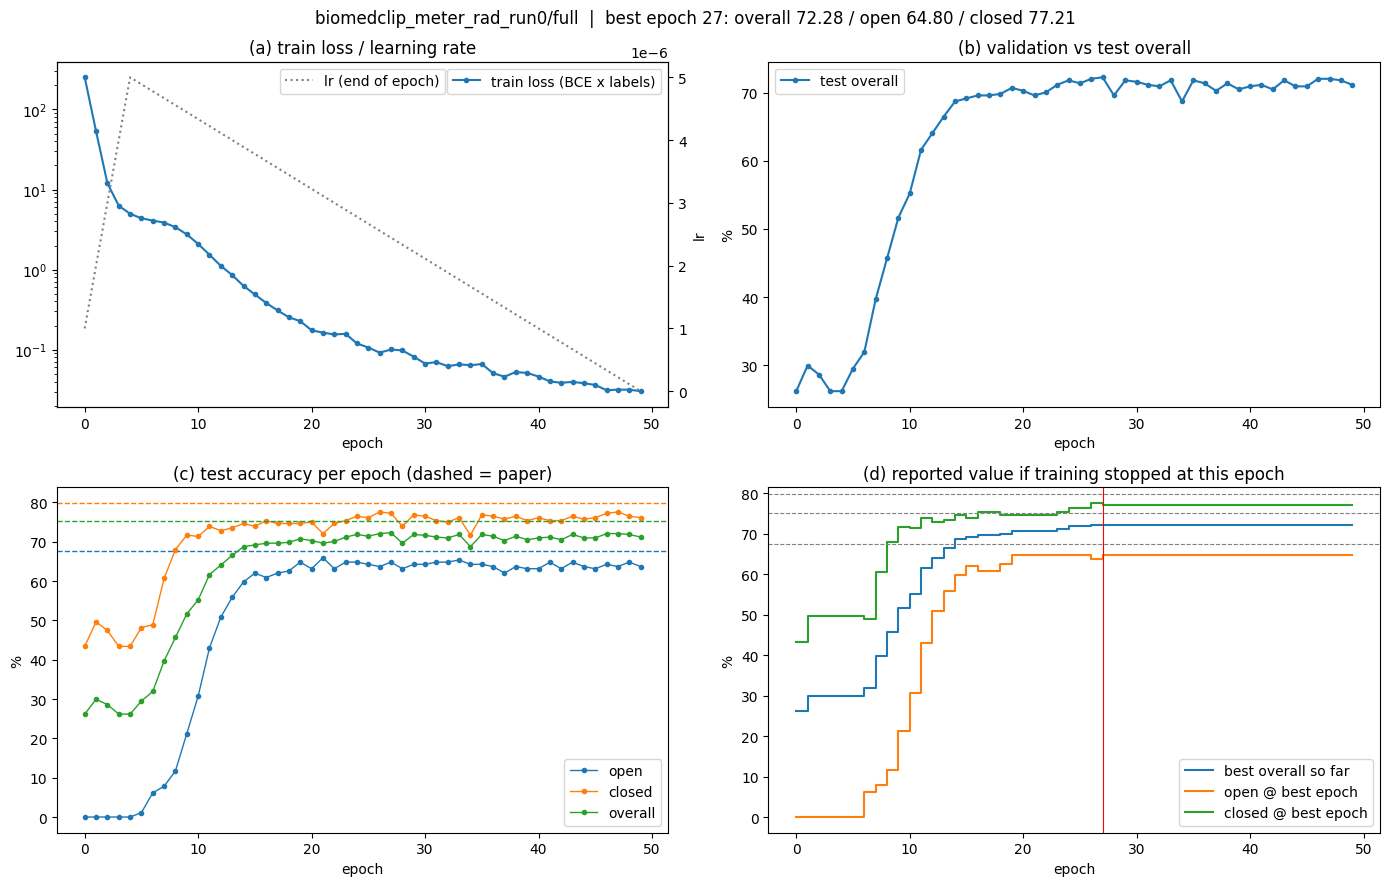

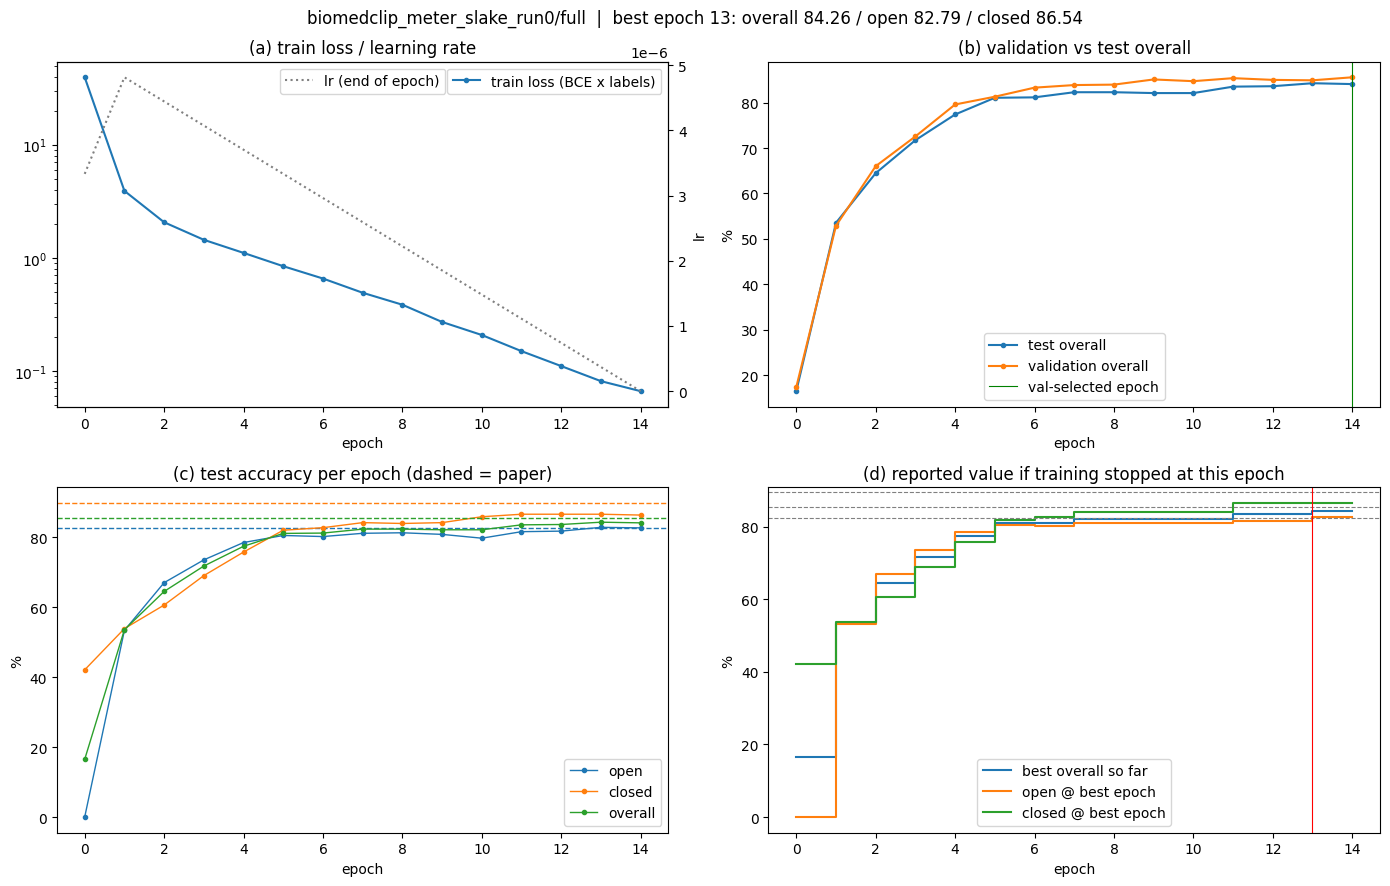

saved to /content/biomedclip_meter/analysis


In [7]:
import json, zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RUN_ROOT = Path('/content/biomedclip_meter')   # 이 폴더 아래의 모든 history.json을 찾습니다
DOWNLOAD = False                               # True면 analysis 폴더를 zip으로 내려받습니다
PAPER = {'rad': (67.6, 79.8, 75.2), 'slake': (82.5, 89.7, 85.4)}   # Open, Closed, Overall
OUT = RUN_ROOT / 'analysis'
OUT.mkdir(parents=True, exist_ok=True)


def load_history(path):
    rows = []
    for h in json.loads(path.read_text(encoding='utf-8')):
        row = {'epoch': h['epoch'], 'train_loss': h['train_loss'], 'lr': h.get('lr')}
        for split in ('test', 'validation'):
            for k, v in (h.get(split) or {}).items():
                row[f'{split}_{k}'] = v
        rows.append(row)
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    # 지금까지의 최고 epoch: QCR/M3AE와 같이 test overall이 '처음으로 더 높아진' epoch
    best_i, best = [], -1.0
    for i, v in enumerate(df['test_overall']):
        if v > best:
            best, bi = v, i
        best_i.append(bi)
    for k in ('overall', 'open', 'closed'):
        df[f'best_{k}'] = df[f'test_{k}'].iloc[best_i].values
    df['best_epoch'] = df['epoch'].iloc[best_i].values
    return df


runs = []
for path in sorted(RUN_ROOT.rglob('history.json')):
    if 'analysis' in path.parts:
        continue
    df = load_history(path)
    if df.empty:
        print('no epochs in', path); continue
    dataset = 'slake' if 'slake' in str(path).lower() else 'rad'
    run = f'{path.parent.parent.name}/{path.parent.name}'     # 예: biomedclip_meter_rad_run0/full
    df.to_csv(OUT / f"epochs_{run.replace('/', '__')}.csv", index=False)
    runs.append({'dataset': dataset, 'name': run, 'path': path, 'df': df})
assert runs, f'{RUN_ROOT} 아래에서 history.json을 찾지 못했습니다'


def run_summary(r):
    df, p = r['df'], PAPER[r['dataset']]
    b, last = df.loc[df['epoch'] == df['best_epoch'].iloc[-1]].iloc[0], df.iloc[-1]
    tail = df.tail(min(5, len(df)))
    s = {'dataset': r['dataset'], 'run': r['name'], 'epochs': len(df),
         'best_epoch': int(b['epoch']), 'best_open': b['test_open'], 'best_closed': b['test_closed'],
         'best_overall': b['test_overall'], 'paper_overall': p[2], 'delta_overall': b['test_overall'] - p[2],
         'last_open': last['test_open'], 'last_closed': last['test_closed'], 'last_overall': last['test_overall'],
         'last5_mean_overall': tail['test_overall'].mean(),
         'max_open (epoch)': f"{df['test_open'].max():.2f} ({int(df.loc[df['test_open'].idxmax(), 'epoch'])})",
         'max_closed (epoch)': f"{df['test_closed'].max():.2f} ({int(df.loc[df['test_closed'].idxmax(), 'epoch'])})",
         'final_train_loss': last['train_loss']}
    if 'validation_overall' in df:   # SLAKE: validation 최고 epoch(동점이면 앞 epoch)의 test 점수
        v = df.loc[df['validation_overall'].idxmax()]
        s.update(val_epoch=int(v['epoch']), val_sel_open=v['test_open'], val_sel_closed=v['test_closed'], val_sel_overall=v['test_overall'])
    return s


table = pd.DataFrame([run_summary(r) for r in runs])
table.to_csv(OUT / 'run_summary.csv', index=False)
display(Markdown('### 실행별 요약\n'
                 '- best = test overall 최고 epoch(QCR·M3AE 방식). val_sel = validation 최고 epoch의 test 점수(SLAKE만).\n'
                 '- max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.'))
display(table.round(2))
cols = [c for c in ('best_open', 'best_closed', 'best_overall', 'last_overall', 'val_sel_overall') if c in table]
display(Markdown('### 데이터셋별 평균 (실행이 여러 개일 때 의미 있음)'))
display(table.groupby('dataset')[cols].agg(['mean', 'std', 'count']).round(2))

for r in runs:
    df, p = r['df'], PAPER[r['dataset']]
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f"{r['name']}  |  best epoch {int(df['best_epoch'].iloc[-1])}: "
                 f"overall {df['best_overall'].iloc[-1]:.2f} / open {df['best_open'].iloc[-1]:.2f} / closed {df['best_closed'].iloc[-1]:.2f}")
    a = ax[0, 0]
    a.plot(df['epoch'], df['train_loss'], marker='.', label='train loss (BCE x labels)')
    a.set_yscale('log'); a.set_title('(a) train loss / learning rate'); a.set_xlabel('epoch')
    if df['lr'].notna().any():
        a2 = a.twinx(); a2.plot(df['epoch'], df['lr'], color='gray', ls=':', label='lr (end of epoch)'); a2.set_ylabel('lr')
        a2.legend(loc='upper center')
    a.legend(loc='upper right')
    a = ax[0, 1]
    a.plot(df['epoch'], df['test_overall'], marker='.', label='test overall')
    if 'validation_overall' in df:
        a.plot(df['epoch'], df['validation_overall'], marker='.', label='validation overall')
        a.axvline(df.loc[df['validation_overall'].idxmax(), 'epoch'], color='green', lw=0.8, label='val-selected epoch')
    a.set_title('(b) validation vs test overall'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 0]
    for col, lab, k in (('test_open', 'open', 0), ('test_closed', 'closed', 1), ('test_overall', 'overall', 2)):
        line, = a.plot(df['epoch'], df[col], marker='.', label=lab, lw=1)
        a.axhline(p[k], ls='--', color=line.get_color(), lw=1)
    a.set_title('(c) test accuracy per epoch (dashed = paper)'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 1]
    a.step(df['epoch'], df['best_overall'], where='post', label='best overall so far')
    a.step(df['epoch'], df['best_open'], where='post', label='open @ best epoch')
    a.step(df['epoch'], df['best_closed'], where='post', label='closed @ best epoch')
    for k in range(3): a.axhline(p[k], ls='--', color='gray', lw=0.8)
    a.axvline(df['best_epoch'].iloc[-1], color='red', lw=0.8)
    a.set_title('(d) reported value if training stopped at this epoch'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / f"curves_{r['name'].replace('/', '__')}.png", dpi=120)
    plt.show()

for dataset in sorted({r['dataset'] for r in runs}):
    group = [r for r in runs if r['dataset'] == dataset]
    if len(group) < 2:
        continue
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    wide = pd.concat({r['name']: r['df'].set_index('epoch')['test_overall'] for r in group}, axis=1)
    best = pd.concat({r['name']: r['df'].set_index('epoch')['best_overall'] for r in group}, axis=1)
    for frame, a, title in ((wide, ax[0], 'test overall per epoch'), (best, ax[1], 'best overall so far')):
        for c in frame: a.plot(frame.index, frame[c], lw=0.6, alpha=0.5)
        m, s = frame.mean(axis=1), frame.std(axis=1)
        a.plot(m.index, m, color='black', label=f'mean of {len(group)} runs')
        a.fill_between(m.index, m - s, m + s, color='black', alpha=0.15, label='±1 std')
        a.axhline(PAPER[dataset][2], ls='--', color='red', label='paper overall')
        a.set_title(f'{dataset}: {title}'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / f'runs_overlay_{dataset}.png', dpi=120)
    plt.show()

print('saved to', OUT)
if DOWNLOAD:
    from google.colab import files
    archive = Path('/content/biomedclip_analysis.zip')
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for f in OUT.iterdir():
            z.write(f, f.name)
    files.download(str(archive))


(a) 그래프: 기록에 open/closed별 loss가 없어서, 전체 train loss와 learning rate를 함께 그립니다.

(b) 그래프: train accuracy 기록이 없어서 그 대신 validation과 test overall을 그립니다. SLAKE는 validation이 가장 높았던 epoch를 초록 세로선으로 표시하고, 그 epoch의 test 점수를 표에 val_sel_*로 넣습니다.
